# Лабораторная работа 4

Матчинг, критерии планирования и линейная свертка.

**Цель:** научить агентов отсеивать несовместимые пары, нормировать критерии и выбирать варианты по взвешенной сумме. Выполнены все три задания самостоятельной работы.

Запускайте ячейки сверху вниз. Здесь содержится весь код, поэтому файлы `.py` проекта не требуются. Зависимости: `pip install thespian pandas openpyxl`. Приложенный Excel с тремя заказами и тремя курьерами сохранен из ЛР3 и встроен в notebook. Существующие Excel и JSON рядом с notebook используются без перезаписи.

## 1 Исходные данные и настройки

Заказы и курьеры читаются из листов Excel. В `planning_config.json` критерии задаются именем, полем варианта и направлением нормировки. Три профиля содержат разные веса; их сумма в каждом профиле равна 1. Чтобы поменять приоритеты, достаточно изменить JSON и повторить вычисления.

In [1]:
from pathlib import Path
import base64
import json
import logging

Path('Отчёты').mkdir(exist_ok=True)
input_bytes = base64.b64decode('UEsDBBQAAAAIAKkAVl2SCoxT9gAAAL4BAAAPAAAAeGwvd29ya2Jvb2sueG1stdGxTsMwEAbgV7FuJ65DSdOobhcWVt7Acc6N1diObBcyVmKEHYmn6IKQeArnjRAFEVUsLGyn+6XTp/9Wm8F05A590M5yYNkMCFrpGm23HPZRXZSwWa+G6t75Xe3cjgyms6EaOLQx9hWlQbZoRMhcj3YwnXLeiBgy57c09B5FE1rEaDqaz2YFNUJb+Lx32oafiVhhkEN6Tsf0no7pbXwEckpuGg4MiK90w+G2XBaK1XkpZLOYL9gSvj3+Lx6nlJZ47eTeoI1fII+diNrZ0Oo+AKG/RC/jw3gYn9LreDgz5ZPpsshzxeqrUrJ5WeA/mOhUGJ1+sf4AUEsDBBQAAAAIAKkAVl0hXzspuQEAAFkHAAANAAAAeGwvc3R5bGVzLnhtbNVVTU/jMBD9K5bvNE1XVKsKg1hEJC5c4LBXJ5mklsYfsl1w99evbOeLSgi6p61yyJsnvzczcTy+uQsSyRtYJ7RitFytKQHV6FaontGD765+0rvbm7Bz/ojwsgfwJEhUbhcY3XtvdkXhmj1I7lbagAoSO20l926lbV84Y4G3LsokFpv1eltILhSNjp1W3pFGH5Rn9MdEpWR/yBtHRsuSkiISikvI1AO3KLxOfDErvqG8t4LjZ7o6rz5PPgCXjATiaTcCMb4N9x6sqgQiGfDr0QCjSiuYHIfFX4p6y4/l5vpsndMo2lxX/6BRW2L7mtGqetzGZ/Rb6Bf+A0id1tq2YKdeSzqTESF0Pn87K/r9AL02GdTaey0zbgXvteI4ZB4tJpiyNYD4Ev+9391JytARdZCV9E8to2tK4laMUCAOMFsNQU60tBxTLNy3/+oeujnN5wblNwy4MXh8PsgabJVOU5IlttJqGQnEOfqVzFL8H5SQ4nsUvZIw7xofiTh0vGji0WpAebDj9oTuEmt/t9y8QsjmZzayuehGNpfVSDEd+A/j5WS4TDyJNwCjz7Fq/HjGl6PEpXC+JG//AlBLAwQUAAAACACqAFZd+lwBWQMDAADaDQAAEwAAAHhsL3RoZW1lL3RoZW1lMS54bWy9V9tymzAU/BVG7w03c/OEZBLHbh/SaafJD8ggQI0QHkmOnb/vIG4CjOM0duwHS2LP2UXnsMLXt/ucaK+IcVzQEJhXBtAQjYoY0zQEW5F888HtzTWciwzlSKMwRyFYZFB8//0MtH1OKJ/DEGRCbOa6zqMM5ZBfFRtE9zlJCpZDwa8KluoxgztM05zolmG4eg4xBW3eJUE5ooKXCxFhT9EBsvJa/GKWP/yNLwjTXiEJwQ7TuNg9o70AGoFcLAgLgSE/QNNvrvU2ioiJYCVwJT9NYB0Rv1gykKXrNtJYWv7M7BgkgogxcOmX3y6jRMAoQrSWo4JNxzV8qwErqGp4IHvgmfYgQGGwxwyBe2/N+gESVQ1n4xtdBcsHpx8gUdXQGQXcGdZ9YPcDJKoauqOA2fLOs5b9AInKCKYvY7jr+b7bwFtMUpAfB/GB6xreQ4PvYLrSalUCKnqN9ytJcIRk3+Xwb8FWBRWyylBgqom3DUpgVDYoJHjNsPaI00xIHjhH8B1AxI8C9AFnjum7Ao5QHyFt6ToGXd0MuTW5mHwkE0zIk3gj6JFLcbwgOF5hQuRERrWl2GQLwhrCHjBlsBvzOlXKtU3BQ2CAyVzSQTAV1ZrrNU89nJNt/rOI66Y3WzuAcw5Fd8FwFJ9oGeQs5aqGEneyDs+e0NHRDXXYJ+qQd3KyEN/8sJDgqBBdKQ/BVIPlKeHMarvlESQoLgtWJ+iV9SwlDmZTd2R9dmtPKDHPYIyavMaUkqlm67rwDEVWpHj+YSVBMCGk3KpLFFkf2wGh/Zm2K/m95u7+yyw2jIsHyLMKJy+15ytVaALD+QIaq9yZy9Howz1ESYIiMbHSTR+5qLMcvPxZdDkptgKxpyzeaWuyZX9gHALHMx0DaDHmoimAFmPWtc/4/aJbh2STwdrJew9thZfjllMRK+UMpffnteJ1ujrLcfV+1MC1puzWm34SL3A+Bsq5pPhH4H/UUyurPPexqepQ5U0arT0hz76Q0XZd+XWGOmzZ0mOb1zE5G/yBalZu/gFQSwMEFAAAAAgAqgBWXQ0euehlAAAAcwAAABQAAAB4bC9zaGFyZWRTdHJpbmdzLnhtbAXBUQrDIAwA0KtI/mfcPsaQ2p5F2rQKJhaTDY+/95ZtcnM/Glq7JHj6AI5k70eVK8HXzscHtnWZUdXc5CYaZ4JidkdE3QtxVt9vksnt7IOzqe/jQr0H5UMLkXHDVwhv5FwFHK5/UEsDBBQAAAAIAKoAVl1dSnZtEQMAAI4OAAAYAAAAeGwvd29ya3NoZWV0cy9zaGVldDEueG1spVfLTttAFP2V0ewbv5IQEA4qTSA8KlXddO0mTmI1tiN7SNJdgEWlUgmp6qrqQ+0XGARqxMP8wp0/qjxxQgrXZTArz8TnnLkz9xzbWV0buT0ysIPQ8T2TagWVEttr+i3H65h0j7WfVehadXW0MvSDd2HXthkZuT0vXBmZtMtYf0VRwmbXdq2w4Pdtb+T22n7gWiws+EFHCfuBbbUEze0puqqWFddyPJoIil83BPhVQFp229rrsdf+sGE7nS4zqVaiREmATb8XplfiOkmRlLjWSFyHTot1TapVKOk6rZbtmVSlpLkXMt99k967lZnS9ZSuz+m6/gi6kdKNfKsXU3oxH72U0kv56OWUXs5HX0rpS/nolZReyUdfTunL+eiaOvONmlNgbrycztNm1ksG0gLKbQREZmoWs5JJ4A9JIEBJXMrlGXkeIBGzZoJ5rlESCtMwk4YsEHcGVfgOMVzBOR8niwymS81J65mkCCYJDa4hhlOI4BomcI5JvMiQ+AYR3+f7EGGkWgbpB5zwj3AOVxipnkH6xQ8gFuXGfJ8f8E8YeSOD/BViiPkYzmAC1xDxA4gI3EAMl/yQfxAHMOHHZIRpbj5N8z2m2XiM5tl0xxDBKVzABK9y6ymKaI3bGYqf+TjpHT/Gdgt/IIILiJIrJrrzsOjd4h6S3M2Q/A0TuMlmKyJ3C/FLXh3MpIb+v/jpYi1DrDV9+w2qGpq5ReRCVV8ghgt+OE0dP+BHaNqkl6lhSLWAYusYVldVNEgY1kDjgSGLqOkxZBk1M4asoCZF94Q6Dz1TdPO7uXp3z1CGjKEM2frXDbyonyIuR3CZuBw1kyHbypp0MXVUs4RbyZBt+6Yh2/YGhlxGrYQhNXRT29LL76CiJdRLj27bPR8VZXxUlG3y+iLy3xcFH0MMJ5k+KsoeT60o+0ioY8hSxiMJw6LITWlkQ/rYtqT3tC2tuYMhM2yU0bWHbaTc+djsWx37pRV0HC8kPbvNTKoWligJppYSY+b3xahEyVufMd+dzbq21bKDZGZQ0vZ9Np9Mv27nfy2rfwFQSwMEFAAAAAgAqgBWXQ8aRE9SAwAAHQ0AABgAAAB4bC93b3Jrc2hlZXRzL3NoZWV0Mi54bWy1l01v2kAQhv/Kau/FBhtC0pioaT5opEpVLz27YD5UjJG9IfRGQU2lEimH9hD1kChV1TOhoaFJcP7C7D+qdu0AacaNQe3BgoV5552dedaG1bWWXSNNy/WqTt2gyYRKiVUvOMVqvWzQXVZ6lKVrudXWyp7jvvEqlsVIy67VvZWWQSuMNVYUxStULNv0Ek7DqrfsWslxbZN5CcctK17DtcyilNk1JaWqGcU2q3UqEspPt2TwC5cUrZK5W2Mvnb28VS1XmEGTaUoUEVhwal74SuyqKJIS22zJ171qkVUMmsxSUqkWi1bdoColhV2POfar8LtpmkCeCuWpiTyVmkOuhXJtMXc9lOuLydOhPD2Ra+oc8kwoz0z3rs8hXwrlS1N5Zg55NpRnF9v7cihfXkyeVG+5UedIoEwBlMRumMwUC9fZI64MErBmMrfiCb4S8oKIeZKkxJMjYwb1mCu/aebgK/ThDIZwxQ9gzHvwi8AYfLiGIW8L32bgPsmzHpHnGxzBMSZ4GiH4Aj74vA3nMIIx9HkH+sK6zz9AP6gGfPgBPoEb8OEKfPgJQxjDiB+SFma08R+M3mJGm5GtHMEN7xE4B5+/Ez4wgCt+CEO45j3+nsAF9OES+nABPgyw1FsRqU95B3wYwXWQmR8QGIiU4MN5uB3C23KUPu/wLpZ7OyL3d7nbO/qeLJXAMGzaiO/zrrBsi70E3cEs8lHlw6UcQVg8Jn0WIT2GM/5RuAb1jfk+9DH9ToT+E2/zrmy4mO55kEuMHClFkSdq5mCJWzIzqJb628FKSWNNGgdPlWYuiR6d2ciZEo9gIHYmmCBwlBAXepAwIxU9CbEjNyNK+gw+XPJuMGsBxGM4kS3rwZUgGGUXbYSK+m7jsShTWGgaRQiL1FBYHs55jwUtDgsakjeFsqDhjT+BIe+IkyJYOEmIC2VBi92/DS02DNo/hEGbAwY0Fm1bXosNAxaZRWGI0ct7NOhxaNDj8rg+G3nnvjmSD5OQh9OEuFAeMCscBz02OZsRVT08fH2O4etx55THInV09vH3uIOG3mXvdvjKH7++GmbZem665WrdIzWrxAyqJpYocQMQ5HvmNOS7NCWvHcYc+3ZVscyi5YqVRknJcdhkEfzcm/zTyf0GUEsDBBQAAAAAAKoAVl01dc9GKAEAACgBAAALAAAAX3JlbHMvLnJlbHPvu788P3htbCB2ZXJzaW9uPSIxLjAiIGVuY29kaW5nPSJ1dGYtOCI/PjxSZWxhdGlvbnNoaXBzIHhtbG5zPSJodHRwOi8vc2NoZW1hcy5vcGVueG1sZm9ybWF0cy5vcmcvcGFja2FnZS8yMDA2L3JlbGF0aW9uc2hpcHMiPjxSZWxhdGlvbnNoaXAgVHlwZT0iaHR0cDovL3NjaGVtYXMub3BlbnhtbGZvcm1hdHMub3JnL29mZmljZURvY3VtZW50LzIwMDYvcmVsYXRpb25zaGlwcy9vZmZpY2VEb2N1bWVudCIgVGFyZ2V0PSIveGwvd29ya2Jvb2sueG1sIiBJZD0iUjlhN2ZhNGZhZjY4ZjQ4Y2IiIC8+PC9SZWxhdGlvbnNoaXBzPlBLAwQUAAAACACqAFZdBDEvmSMBAACRAwAAGgAAAHhsL19yZWxzL3dvcmtib29rLnhtbC5yZWxzzdO7bsMgFAbgV0HsNcZ2gFRxsnTpmuYFCBxsK1wsIK3zbB36SH2FqhdVdtWhS6QuDD/Sr49zxOvzy2Y3OYseIaYh+BbTosQIvAp68F2Lz9ncCLzbbvZgZR6CT/0wJjQ561OL+5zHW0KS6sHJVIQR/OSsCdHJnIoQOzJKdZIdkKosGYnzDrzsRIfLCH9pDMYMCu6COjvw+ZdikvLFQsLoIGMHucVksl9ZMTmL0b1u8V4Z4FquSqUq1ph6hRG5Gij34GDp+Yg+TzpTcUoV1RpKfmSNrOGaqtTLCPohx8F3P6c1v5rxGKc1K2m9ZkI3nIpr8p5CPKUeIC9p3/H7AwDyfHpizQw9VkIqzRtO1/+AV815NasqQ48roWgj2OdyyeJjbd8AUEsDBBQAAAAIAKoAVl2hO89OGwEAANwDAAATAAAAW0NvbnRlbnRfVHlwZXNdLnhtbLWTQU7DMBBFrxJ5i2K3XSCEknYBbAEJLmA5k8SqPbY8k5KejQVH4gqoLqoAIUVV241nM37v/8V8vn9Uq9G7YgOJbMBazOVMFIAmNBa7WgzcljditaxetxGoGL1DqkXPHG+VItOD1yRDBBy9a0PymkmG1KmozVp3oBaz2bUyARmQS94xxLK6h1YPjouHkQH32tE7Udzt93aqWugYnTWabUC1weaPpAxtaw00wQwekCXFBLqhHoC9k3lKry1eZbD615nA0XHS71Yygcs71NtIB8XTBlKyDRTPOvGj9lALNTpFvHVA8swNM3RKzT142L/zkwNkzGTZXidoXjhZ7M7e+Sd7KshbSOv8kVQep/f/HebAPzbI4uJBVL7V5RdQSwECFAMUAAAACACpAFZdkgqMU/YAAAC+AQAADwAAAAAAAAAAAAAApIEAAAAAeGwvd29ya2Jvb2sueG1sUEsBAhQDFAAAAAgAqQBWXSFfOym5AQAAWQcAAA0AAAAAAAAAAAAAAKSBIwEAAHhsL3N0eWxlcy54bWxQSwECFAMUAAAACACqAFZd+lwBWQMDAADaDQAAEwAAAAAAAAAAAAAApIEHAwAAeGwvdGhlbWUvdGhlbWUxLnhtbFBLAQIUAxQAAAAIAKoAVl0NHrnoZQAAAHMAAAAUAAAAAAAAAAAAAACkgTsGAAB4bC9zaGFyZWRTdHJpbmdzLnhtbFBLAQIUAxQAAAAIAKoAVl1dSnZtEQMAAI4OAAAYAAAAAAAAAAAAAACkgdIGAAB4bC93b3Jrc2hlZXRzL3NoZWV0MS54bWxQSwECFAMUAAAACACqAFZdDxpET1IDAAAdDQAAGAAAAAAAAAAAAAAApIEZCgAAeGwvd29ya3NoZWV0cy9zaGVldDIueG1sUEsBAhQDFAAAAAAAqgBWXTV1z0YoAQAAKAEAAAsAAAAAAAAAAAAAAKSBoQ0AAF9yZWxzLy5yZWxzUEsBAhQDFAAAAAgAqgBWXQQxL5kjAQAAkQMAABoAAAAAAAAAAAAAAKSB8g4AAHhsL19yZWxzL3dvcmtib29rLnhtbC5yZWxzUEsBAhQDFAAAAAgAqgBWXaE7z04bAQAA3AMAABMAAAAAAAAAAAAAAKSBTRAAAFtDb250ZW50X1R5cGVzXS54bWxQSwUGAAAAAAkACQBJAgAAmREAAAAA')
if not Path('Исходные данные.xlsx').exists():
    Path('Исходные данные.xlsx').write_bytes(input_bytes)
config_text = '{\n  "default_profile": "Стоимость",\n  "criteria": [\n    {"name": "start_efficiency", "field": "pickup", "direction": "decreasing"},\n    {"name": "finish_efficiency", "field": "time_to", "direction": "decreasing"},\n    {"name": "price_efficiency", "field": "price", "direction": "decreasing"},\n    {"name": "pickup_accuracy_efficiency", "field": "pickup_deviation", "direction": "decreasing"}\n  ],\n  "profiles": {\n    "Стоимость": {"start_efficiency": 0.1, "finish_efficiency": 0.1, "price_efficiency": 0.7, "pickup_accuracy_efficiency": 0.1},\n    "Скорость": {"start_efficiency": 0.2, "finish_efficiency": 0.6, "price_efficiency": 0.1, "pickup_accuracy_efficiency": 0.1},\n    "Точность получения": {"start_efficiency": 0.05, "finish_efficiency": 0.05, "price_efficiency": 0.1, "pickup_accuracy_efficiency": 0.8}\n  }\n}\n'
if not Path('planning_config.json').exists():
    Path('planning_config.json').write_text(config_text, encoding='utf-8')
logging.basicConfig(level=logging.INFO, format='%(message)s', force=True,
                    handlers=[logging.FileHandler('output_lab4.txt', encoding='utf-8', mode='w')])
print(Path('planning_config.json').read_text(encoding='utf-8'))


{
  "default_profile": "ЛР6",
  "criteria": [
    {
      "name": "start_efficiency",
      "field": "pickup",
      "direction": "decreasing"
    },
    {
      "name": "finish_efficiency",
      "field": "time_to",
      "direction": "decreasing"
    },
    {
      "name": "price_efficiency",
      "field": "price",
      "direction": "decreasing"
    },
    {
      "name": "pickup_accuracy_efficiency",
      "field": "pickup_deviation",
      "direction": "decreasing"
    }
  ],
  "profiles": {
    "ЛР6": {
      "start_efficiency": 0.2,
      "finish_efficiency": 0.3,
      "price_efficiency": 0.5,
      "pickup_accuracy_efficiency": 0
    }
  }
}



In [2]:
import pandas as pd


def get_excel_data(filename, sheet_name):
    return list(pd.read_excel(filename, sheet_name=sheet_name).to_dict('index').values())

import json
import math


def load_planning_config(filename='planning_config.json', profile=None):
    with open(filename, encoding='utf-8') as file:
        config = json.load(file)
    profile = profile or config['default_profile']
    weights = config['profiles'][profile]
    criteria = [{**item, 'weight': weights[item['name']]} for item in config['criteria']]
    if not criteria or len({c['name'] for c in criteria}) != len(criteria):
        raise ValueError('Критерии должны быть непустыми и иметь уникальные имена')
    if any(c['direction'] not in ('increasing', 'decreasing') for c in criteria):
        raise ValueError('Неизвестное направление нормировки')
    if any(not math.isfinite(c['weight']) or c['weight'] < 0 for c in criteria):
        raise ValueError('Веса должны быть конечными неотрицательными числами')
    if not math.isclose(sum(c['weight'] for c in criteria), 1.0, abs_tol=1e-9):
        raise ValueError('Сумма весов должна быть равна единице')
    return profile, criteria


In [3]:
order_data = get_excel_data('Исходные данные.xlsx', 'Заказы')
courier_data = get_excel_data('Исходные данные.xlsx', 'Курьеры')
print(pd.DataFrame(order_data).to_string(index=False))
print(pd.DataFrame(courier_data).to_string(index=False))


 Номер Наименование  Масса  Объем  Стоимость  Координата получения x  Координата получения y  Координата доставки x  Координата доставки y  Время получения заказа  Время доставки заказа Тип заказа
     1    Документы      1    0.1        200                       3                       4                      6                      8                       2                     10  Документы
     2      Посылка      3    2.0        350                       6                       8                      9                     12                       8                     15    Посылка
     3      Коробка      8    4.0        500                       0                       0                      3                      4                       3                     15    Посылка
 Табельный номер           ФИО  Координата начального положения x  Координата начального положения y Типы доставляемых заказов  Стоимость выхода на работу  Цена работы за единицу времени  Скорость  Объем ранца  Г

## 2 Сцена и сущности

Scene хранит сущности по типам. Point вычисляет евклидово расстояние. OrderEntity хранит параметры заказа и выбранный вариант. CourierEntity хранит ограничения и расписание. ScheduleItem описывает действие курьера. Сохраняются три записи на заказ и поиск пересечений из предыдущей работы.

**message.py**

In [4]:
"""Сообщения протокола планирования ЛР4."""

from dataclasses import dataclass
from enum import Enum
from typing import Any


class MessageType(Enum):
    INIT_MESSAGE = 'Инициализация'
    PRICE_REQUEST = 'Запрос параметров'
    PRICE_RESPONSE = 'Ответ с параметрами'
    PLANNING_REQUEST = 'Запрос планирования'
    PLANNING_RESPONSE = 'Результат планирования'


@dataclass
class Message:
    msg_type: MessageType
    msg_body: Any = None


**point.py**

In [5]:
"""Точка и евклидово расстояние."""

import math
from dataclasses import dataclass


@dataclass
class Point:
    x: float
    y: float

    def __repr__(self):
        return f'({self.x:g}; {self.y:g})'

    def get_distance_to_other(self, other_point):
        return math.dist((self.x, self.y), (other_point.x, other_point.y))


**scene.py**

In [6]:
"""Сцена сущностей виртуального мира."""

from collections import defaultdict


class Scene:
    def __init__(self):
        self.entities = defaultdict(list)

    def get_entities_by_type(self, entity_type):
        return self.entities.get(entity_type, [])


**entities/base_entity.py**

In [7]:
class BaseEntity:
    def __init__(self, onto_desc, scene=None):
        self.onto_description = onto_desc
        self.name = onto_desc.get('data', {}).get('label', {}).get('value')
        self.uri = 'UNKNOWN_URI'
        self.scene = scene


**entities/order_entity.py**

In [8]:
class OrderEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Номер']
        self.name = init_dict_data['Наименование']
        self.weight = float(init_dict_data['Масса'])
        self.volume = float(init_dict_data['Объем'])
        self.price = float(init_dict_data['Стоимость'])
        self.point_from = Point(float(init_dict_data['Координата получения x']),
                                float(init_dict_data['Координата получения y']))
        self.point_to = Point(float(init_dict_data['Координата доставки x']),
                              float(init_dict_data['Координата доставки y']))
        self.time_from = float(init_dict_data['Время получения заказа'])
        self.time_to = float(init_dict_data['Время доставки заказа'])
        self.order_type = init_dict_data['Тип заказа']
        self.uri = 'Order' + str(self.number)
        self.assigned_courier = None
        self.selected_variant = None

    def get_type(self):
        return 'ORDER'


**schedule_item.py**

In [9]:
from dataclasses import dataclass



@dataclass
class ScheduleItem:
    order: OrderEntity
    rec_type: str
    start_time: float
    end_time: float
    point_from: Point
    point_to: Point
    cost: float
    all_params: dict


## 3 Варианты asap и точно в срок

`asap` начинается сразу после последней записи расписания. По формуле ЛР4 он не откладывает получение до желаемого времени. В отличие от запуска ЛР3, раннее получение и ранняя доставка теперь возможны и оцениваются критериями. `jit_pickup` начинает движение так, чтобы прибыть к желаемому времени получения. `jit_delivery` рассчитывает начало движения от желаемого времени доставки за вычетом полного времени пути.

Как в методичке, JIT-варианты предлагаются только при пустом расписании и положительном времени выхода. Цена равна времени движения, умноженному на ставку. Ожидание в точке получения имеет нулевую длительность, а простой до выхода на JIT-маршрут не включается в стоимость. Стоимость выхода на работу читается из Excel, но не входит в формулу цены данной работы. Перед подтверждением предложение пересчитывается, чтобы исключить устаревший вариант.

**entities/courier_entity.py**

In [10]:
import math



class CourierEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Табельный номер']
        self.name = init_dict_data['ФИО']
        self.point = Point(float(init_dict_data['Координата начального положения x']),
                           float(init_dict_data['Координата начального положения y']))
        self.types = [item.strip() for item in init_dict_data['Типы доставляемых заказов'].split(';')]
        self.start_cost = float(init_dict_data['Стоимость выхода на работу'])
        self.rate = float(init_dict_data['Цена работы за единицу времени'])
        self.velocity = float(init_dict_data['Скорость'])
        self.max_volume = float(init_dict_data['Объем ранца'])
        self.max_mass = float(init_dict_data['Грузоподъемность'])
        self.schedule = []
        self.uri = 'Courier' + str(self.number)

    def get_type(self):
        return 'COURIER'

    def get_last_point(self):
        return self.schedule[-1].point_to if self.schedule else self.point

    def get_last_time(self):
        return self.schedule[-1].end_time if self.schedule else 0.0

    def get_conflicts(self, start_time, end_time):
        # Полуоткрытые интервалы: касание границ конфликтом не считается.
        if start_time >= end_time:
            return []
        return [item for item in self.schedule
                if item.start_time < item.end_time
                and item.start_time < end_time and start_time < item.end_time]

    def get_variants(self, order):
        if (order.order_type not in self.types or order.weight > self.max_mass
                or order.volume > self.max_volume or self.velocity <= 0):
            return []
        start = self.get_last_time()
        time_to_order = self.get_last_point().get_distance_to_other(order.point_from) / self.velocity
        time_with_order = order.point_from.get_distance_to_other(order.point_to) / self.velocity
        duration = time_to_order + time_with_order

        def make_variant(departure, name):
            pickup = departure + time_to_order
            return {'courier': self, 'order': order, 'time_from': departure,
                    'time_to': pickup + time_with_order, 'arrival': pickup, 'pickup': pickup,
                    'price': duration * self.rate, 'point_from': self.get_last_point(),
                    'variant_name': name, 'pickup_deviation': abs(pickup - order.time_from)}

        variants = [make_variant(start, 'asap')]
        # Как в методичке: JIT предлагается для пока пустого расписания.
        if not self.schedule:
            pickup_departure = order.time_from - time_to_order
            if pickup_departure > 0:
                variants.append(make_variant(pickup_departure, 'jit_pickup'))
            delivery_departure = order.time_to - duration
            if delivery_departure > 0:
                variants.append(make_variant(delivery_departure, 'jit_delivery'))
        return variants

    def add_order_to_schedule(self, order, start_time, end_time, price, params):
        # Пересчитываем предложение: после ответа другому заказу оно могло устареть.
        variants = self.get_variants(order)
        if not variants:
            return False
        current = next((v for v in variants if v['variant_name'] == params['variant_name']), None)
        if current is None:
            return False
        if (self.get_conflicts(start_time, end_time)
                or params['point_from'] != current['point_from']
                or any(not math.isclose(params[key], current[key], abs_tol=1e-9)
                       for key in ('time_from', 'time_to', 'price', 'arrival', 'pickup'))):
            return False
        arrival, pickup = params['arrival'], params['pickup']
        self.schedule.extend([
            ScheduleItem(order, 'Движение за грузом', start_time, arrival,
                         self.get_last_point(), order.point_from, (arrival - start_time) * self.rate, params),
            ScheduleItem(order, 'Ожидание', arrival, pickup,
                         order.point_from, order.point_from, (pickup - arrival) * self.rate, params),
            ScheduleItem(order, 'Движение с грузом', pickup, end_time,
                         order.point_from, order.point_to, (end_time - pickup) * self.rate, params),
        ])
        return True


## 4 Нормировка критериев

Функции нормировки находятся в AgentBase. Для убывающей функции минимум дает 1, максимум — 0; для возрастающей — наоборот. При одинаковых границах возвращается 1: критерий не различает варианты. Выход за диапазон дает −1 как признак недопустимого значения. Как в методичке, проверка совпадения границ выполняется первой.

**Исправления примера методички:** возрастающая оценка доставки предпочитает более позднее завершение, поэтому для минимизации времени доставки использована убывающая функция. Поле `time_from` означает выход курьера, поэтому время получения заказа оценивается по фактическому `pickup`. Это различие особенно важно для курьеров, находящихся на разном расстоянии от заказа.

**agent_base.py**

In [11]:
"""Базовый агент: подписки, диспетчеризация и инициализация."""

import logging

from thespian.actors import Actor



class AgentBase(Actor):
    def __init__(self):
        self.name = type(self).__name__
        self.handlers = {}
        self.subscribe(MessageType.INIT_MESSAGE, self.handle_init_message)

    def subscribe(self, msg_type, handler):
        self.handlers[msg_type] = handler

    def receiveMessage(self, message, sender):
        if not isinstance(message, Message):
            return
        handler = self.handlers.get(message.msg_type)
        if handler is None:
            logging.warning('%s: нет обработчика %s', self.name, message.msg_type)
            return
        logging.info('%s <- %s: %s', self.name, sender, message.msg_type.value)
        try:
            handler(message, sender)
        except Exception:
            logging.exception('Ошибка обработки сообщения агентом %s', self.name)
            raise

    def handle_init_message(self, message, sender):
        self.scene = message.msg_body['scene']
        self.dispatcher = message.msg_body['dispatcher']
        self.entity = message.msg_body['entity']
        self.name += ' ' + self.entity.name

    def send(self, target, message):
        self.dispatcher.message_counts[message.msg_type.value] += 1
        super().send(target, message)

    @staticmethod
    def get_decreasing_kpi_value(value, min_value, max_value):
        if max_value == min_value:
            return 1
        if value > max_value or value < min_value:
            return -1
        if abs(value - min_value) < 0.000001:
            return 1
        if abs(value - max_value) < 0.000001:
            return 0
        return 1 - (value - min_value) / (max_value - min_value)

    @staticmethod
    def get_increasing_kpi_value(value, min_value, max_value):
        if max_value == min_value:
            return 1
        if value > max_value or value < min_value:
            return -1
        if abs(value - min_value) < 0.000001:
            return 0
        if abs(value - max_value) < 0.000001:
            return 1
        return (value - min_value) / (max_value - min_value)


In [12]:
print('Убывающая:', [AgentBase.get_decreasing_kpi_value(x, 10, 20) for x in (10, 15, 20)])
print('Возрастающая:', [AgentBase.get_increasing_kpi_value(x, 10, 20) for x in (10, 15, 20)])
print('За диапазоном:', AgentBase.get_decreasing_kpi_value(25, 10, 20))
print('Равные границы:', AgentBase.get_decreasing_kpi_value(10, 10, 10))


Убывающая: [1, 0.5, 0]
Возрастающая: [0, 0.5, 1]
За диапазоном: -1
Равные границы: 1


## 5 Матчинг и оценка вариантов

Заказ исключает курьеров по типу груза до отправки PRICE_REQUEST. Курьер проверяет массу и объем; если ограничение превышено, возвращает пустой список. Заказ ждет все ответы, находит границы критериев среди полученных вариантов и вычисляет линейную свертку. Выбирается максимум; при равенстве сохраняется порядок поступления предложений.

**Дополнительный критерий заказа** — абсолютное отклонение фактического времени получения от желаемого: `abs(pickup - order.time_from)`. Чем меньше отклонение, тем лучше. Оно нормируется убывающей функцией по всем доступным предложениям. В отличие от критерия раннего получения, этот критерий штрафует и опережение, и опоздание.

В JSON вынесены не только веса, но и состав критериев, поля и направления. `total_efficiency` равна сумме произведений весов на нормированные оценки. В логе записываются все варианты с четырьмя оценками и итоговой сверткой.

**reference_book.py**

In [13]:
import logging


class ReferenceBook:
    def __init__(self):
        self.agents_entities = {}

    def add_agent(self, entity, agent_address):
        self.agents_entities[entity] = agent_address

    def get_address(self, entity):
        address = self.agents_entities.get(entity)
        if address is None:
            logging.error('Агент %s отсутствует в адресной книге', entity.uri)
        return address


**courier_agent.py**

In [14]:
import logging



class CourierAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.subscribe(MessageType.PRICE_REQUEST, self.handle_price_request)
        self.subscribe(MessageType.PLANNING_REQUEST, self.handle_planning_request)

    def handle_price_request(self, message, sender):
        order = message.msg_body
        if order.weight > self.entity.max_mass or order.volume > self.entity.max_volume:
            logging.info('%s: заказ %s исключен по массе или объему', self.name, order.number)
            variants = []
        else:
            variants = self.entity.get_variants(order)
        logging.info('%s: варианты %s', self.name,
                     [(v['time_from'], v['time_to'], v['price']) for v in variants])
        self.send(sender, Message(MessageType.PRICE_RESPONSE, variants))

    def handle_planning_request(self, message, sender):
        params = message.msg_body
        accepted = self.entity.add_order_to_schedule(
            params['order'], params['time_from'], params['time_to'], params['price'], params)
        logging.info('%s: %s, заказ %s', self.name,
                     'Принято' if accepted else 'Отказ, вариант уже невыполним', params['order'].number)
        self.send(sender, Message(MessageType.PLANNING_RESPONSE, accepted))


**order_agent.py**

In [15]:
import logging



class OrderAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.possible_variants = []
        self.unchecked_couriers = []
        self.selected_variant = None
        self.subscribe(MessageType.PRICE_RESPONSE, self.handle_price_response)
        self.subscribe(MessageType.PLANNING_RESPONSE, self.handle_planning_response)

    def handle_init_message(self, message, sender):
        super().handle_init_message(message, sender)
        self.send_params_request()

    def send_params_request(self):
        self.possible_variants = []
        couriers = []
        for courier in self.scene.get_entities_by_type('COURIER'):
            if self.entity.order_type not in courier.types:
                logging.info('%s: курьер %s исключен по типу груза %s',
                             self.name, courier.name, self.entity.order_type)
                continue
            couriers.append(courier)
        self.unchecked_couriers = [self.dispatcher.reference_book.get_address(c) for c in couriers]
        if not self.unchecked_couriers:
            logging.info('%s: нет курьеров', self.name)
        for address in self.unchecked_couriers[:]:
            self.send(address, Message(MessageType.PRICE_REQUEST, self.entity))

    def handle_price_response(self, message, sender):
        self.possible_variants.extend(message.msg_body)
        self.unchecked_couriers.remove(sender)
        if not self.unchecked_couriers:
            self.run_planning()

    def evaluate_variants(self):
        if not self.possible_variants:
            return
        for variant in self.possible_variants:
            variant['total_efficiency'] = 0.0
        for criterion in self.dispatcher.criteria:
            values = [v[criterion['field']] for v in self.possible_variants]
            normalize = (self.get_decreasing_kpi_value if criterion['direction'] == 'decreasing'
                         else self.get_increasing_kpi_value)
            for variant in self.possible_variants:
                score = normalize(variant[criterion['field']], min(values), max(values))
                variant[criterion['name']] = score
                variant['total_efficiency'] += criterion['weight'] * score
        for variant in self.possible_variants:
            logging.info('%s: %s', self.name,
                         {**variant, 'courier': variant['courier'].name,
                          'order': variant['order'].number})

    def run_planning(self):
        if not self.possible_variants:
            logging.info('%s: подходящий вариант отсутствует', self.name)
            return
        self.evaluate_variants()
        # Стабильная сортировка сохраняет порядок предложений при равных оценках.
        self.possible_variants.sort(key=lambda v: v['total_efficiency'], reverse=True)
        self.selected_variant = self.possible_variants.pop(0)
        address = self.dispatcher.reference_book.get_address(self.selected_variant['courier'])
        self.send(address, Message(MessageType.PLANNING_REQUEST, self.selected_variant))

    def handle_planning_response(self, message, sender):
        if message.msg_body:
            self.entity.assigned_courier = self.selected_variant['courier']
            self.entity.selected_variant = self.selected_variant
        elif self.possible_variants:
            self.run_planning()
        else:
            # Все ранее предложенные варианты заняты: запрашиваем актуальные.
            self.send_params_request()


**agents_dispatcher.py**

In [16]:
from collections import Counter

from thespian.actors import ActorSystem



TYPES_AGENTS = {'ORDER': OrderAgent, 'COURIER': CourierAgent}


class AgentsDispatcher:
    def __init__(self, scene, criteria):
        # Учебная сцена передается по ссылке в одном процессе.
        self.actor_system = ActorSystem('simpleSystemBase', logDefs=False)
        self.reference_book = ReferenceBook()
        self.scene = scene
        self.criteria = criteria
        self.message_counts = Counter()

    def add_entity(self, entity):
        agent_type = TYPES_AGENTS.get(entity.get_type())
        if agent_type is None:
            return False
        self.scene.entities[entity.get_type()].append(entity)
        self.create_agent(agent_type, entity)
        return True

    def create_agent(self, agent_class, entity):
        address = self.actor_system.createActor(agent_class)
        self.reference_book.add_agent(entity, address)
        init_data = {'dispatcher': self, 'scene': self.scene, 'entity': entity}
        self.actor_system.tell(address, Message(MessageType.INIT_MESSAGE, init_data))


## 6 Запуск планирования

Thespian simpleSystemBase выполняет агентов в одном процессе. Сначала создаются курьеры, затем заказы; каждый заказ сам выбирает исполнителя по свертке. Записи сохраняются в CSV, лог — в output_lab4.txt. Профиль по умолчанию «Стоимость» задается в JSON.

**utils/schedule_utils.py**

In [17]:
import csv


def save_schedule(scene, filename):
    with open(filename, 'w', encoding='utf-8-sig', newline='') as file:
        writer = csv.writer(file, delimiter=';')
        writer.writerow(['Курьер', 'Заказ', 'Действие', 'Начало', 'Конец', 'Откуда', 'Куда', 'Стоимость', 'Вариант'])
        for courier in scene.get_entities_by_type('COURIER'):
            for item in courier.schedule:
                writer.writerow([courier.name, item.order.number, item.rec_type,
                                 round(item.start_time, 4), round(item.end_time, 4),
                                 item.point_from, item.point_to, round(item.cost, 4),
                                 item.all_params['variant_name']])


**main.py**

In [18]:
"""ЛР4. Запуск: python main.py. Сравнение весов: python experiment.py."""

import logging
from pathlib import Path



def plan_orders(courier_data, order_data, criteria):
    scene = Scene()
    dispatcher = AgentsDispatcher(scene, criteria)
    try:
        # Курьеры должны быть в сцене до начала переговоров заказов.
        for row in courier_data:
            dispatcher.add_entity(CourierEntity({}, row, scene))
        for row in order_data:
            dispatcher.add_entity(OrderEntity({}, row, scene))
        return scene, dict(dispatcher.message_counts)
    finally:
        dispatcher.actor_system.shutdown()


def main(input_file='Исходные данные.xlsx', output_file='Отчёты/Расписание_ЛР4.csv',
         config_file='planning_config.json', profile=None):
    profile, criteria = load_planning_config(config_file, profile)
    scene, counts = plan_orders(get_excel_data(input_file, 'Курьеры'),
                               get_excel_data(input_file, 'Заказы'), criteria)
    save_schedule(scene, output_file)
    for order in scene.get_entities_by_type('ORDER'):
        courier = order.assigned_courier
        variant = order.selected_variant
        details = (f", {variant['variant_name']}, цена {variant['price']:.4f}, "
                   f"оценка {variant['total_efficiency']:.4f}" if variant else '')
        print(f'Заказ {order.number}: {courier.name if courier else "не назначен"}{details}')
    print('Профиль:', profile)
    print('Сообщений переговоров:', sum(counts.values()))
    print('Расписание:', output_file)
    return scene, counts


In [19]:
scene, message_counts = main()
print(pd.read_csv('Отчёты/Расписание_ЛР4.csv', sep=';').to_string(index=False))


Заказ 1: Иванов И. И., asap, цена 20.0000, оценка 1.0000
Заказ 2: Иванов И. И., asap, цена 10.0000, оценка 0.9881
Заказ 3: Сидоров С. С., asap, цена 30.0000, оценка 0.9729
Профиль: ЛР6
Сообщений переговоров: 22
Расписание: Отчёты/Расписание_ЛР4.csv
       Курьер  Заказ           Действие  Начало  Конец  Откуда    Куда  Стоимость Вариант
 Иванов И. И.      1 Движение за грузом     0.0   1.00  (0; 0)  (3; 4)       10.0    asap
 Иванов И. И.      1           Ожидание     1.0   1.00  (3; 4)  (3; 4)        0.0    asap
 Иванов И. И.      1  Движение с грузом     1.0   2.00  (3; 4)  (6; 8)       10.0    asap
 Иванов И. И.      2 Движение за грузом     2.0   2.00  (6; 8)  (6; 8)        0.0    asap
 Иванов И. И.      2           Ожидание     2.0   2.00  (6; 8)  (6; 8)        0.0    asap
 Иванов И. И.      2  Движение с грузом     2.0   3.00  (6; 8) (9; 12)       10.0    asap
Сидоров С. С.      3 Движение за грузом     0.0   2.50 (0; 10)  (0; 0)       20.0    asap
Сидоров С. С.      3           

## 7 Демонстрация трех вариантов и диаграмма

Для первого курьера и первого заказа доступны все три варианта. В `jit_pickup` получение происходит точно в 2, в `jit_delivery` доставка — точно в 10. Эта ячейка показывает допустимые предложения до назначения заказа.

In [20]:
demo_courier = CourierEntity({}, courier_data[0])
demo_order = OrderEntity({}, order_data[0])
demo_variants = demo_courier.get_variants(demo_order)
print(pd.DataFrame([{k: v[k] for k in ('variant_name', 'time_from', 'pickup', 'time_to', 'price')}
                    for v in demo_variants]).to_string(index=False))


variant_name  time_from  pickup  time_to  price
        asap        0.0     1.0      2.0   20.0
  jit_pickup        1.0     2.0      3.0   20.0
jit_delivery        8.0     9.0     10.0   20.0


Диаграмма показывает успешный матчинг, исключение по типу без запроса, отказ по массе или объему пустым списком, оценку предложений и подтверждение либо отказ при планировании. Участники схемы условные и иллюстрируют ветви протокола.

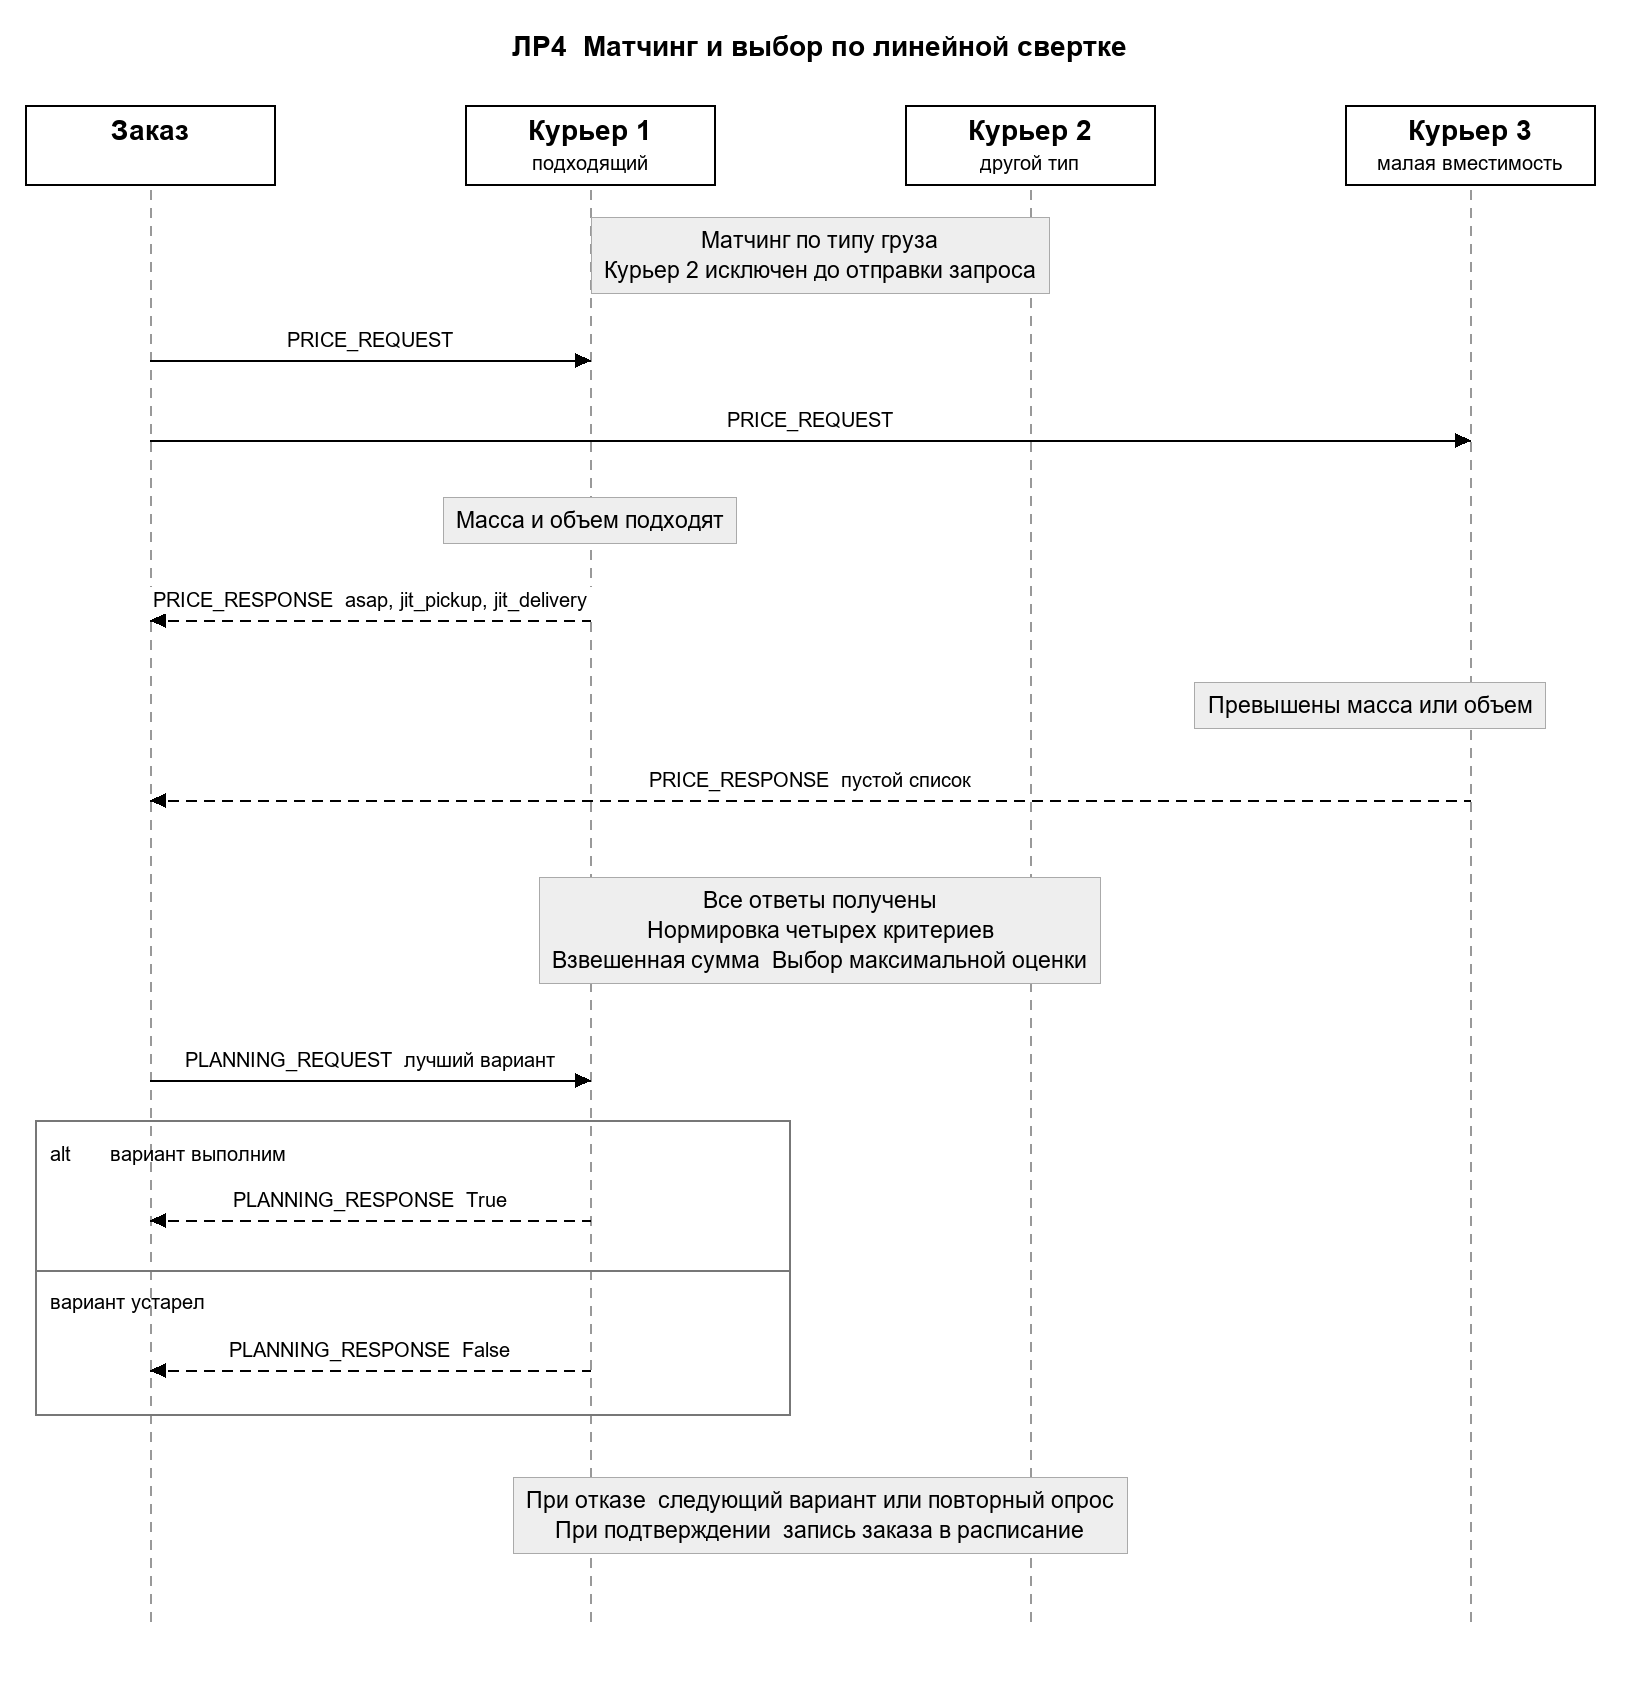

## 8 Три прогона с разными весами

Все профили используют один и тот же Excel и одинаковый порядок заказов. Каждый прогон начинает с пустых расписаний. Стоимость плана равна сумме стоимости действий. Попадание доставки в окно означает `order.time_from <= фактическое время доставки <= order.time_to`, границы включены с допуском 1e-9. Это показатель сравнения; временные пожелания не являются жесткими ограничениями для всех вариантов. Не назначенные заказы не считаются доставленными. Сохраняются таблица сравнения и отдельное расписание каждого профиля.

In [21]:
"""ЛР4: три прогона на одинаковых данных с разными весами критериев."""

import csv
import json
from pathlib import Path



def run_experiment(input_file='Исходные данные.xlsx', config_file='planning_config.json',
                   output_dir='Отчёты'):
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    couriers = get_excel_data(input_file, 'Курьеры')
    orders = get_excel_data(input_file, 'Заказы')
    with open(config_file, encoding='utf-8') as file:
        config = json.load(file)
    rows = []
    for profile in config['profiles']:
        _, criteria = load_planning_config(config_file, profile)
        weights = {item['name']: item['weight'] for item in criteria}
        # Каждый прогон создает новые сущности с пустыми расписаниями.
        scene, _ = plan_orders(couriers, orders, criteria)
        save_schedule(scene, output_dir / f'Расписание_ЛР4_{profile}.csv')
        assigned = [o for o in scene.get_entities_by_type('ORDER') if o.selected_variant]
        in_window = sum(o.time_from - 1e-9 <= o.selected_variant['time_to'] <= o.time_to + 1e-9
                        for o in assigned)
        row = {'Профиль': profile,
               'Вес получения': weights.get('start_efficiency', 0),
               'Вес доставки': weights.get('finish_efficiency', 0),
               'Вес стоимости': weights.get('price_efficiency', 0),
               'Вес точности получения': weights.get('pickup_accuracy_efficiency', 0),
               'Стоимость плана': round(sum(item.cost for courier in scene.get_entities_by_type('COURIER')
                                            for item in courier.schedule), 4),
               'Назначено': len(assigned), 'Доставлено в окне': in_window}
        rows.append(row)
        print(row)
    with (output_dir / 'Сравнение_ЛР4.csv').open('w', encoding='utf-8-sig', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]), delimiter=';')
        writer.writeheader()
        writer.writerows(rows)
    return rows


In [22]:
log_level = logging.getLogger().level
logging.getLogger().setLevel(logging.WARNING)
try:
    comparison_rows = run_experiment()
finally:
    logging.getLogger().setLevel(log_level)
print(pd.DataFrame(comparison_rows).to_string(index=False))


{'Профиль': 'ЛР6', 'Вес получения': 0.2, 'Вес доставки': 0.3, 'Вес стоимости': 0.5, 'Вес точности получения': 0, 'Стоимость плана': 60.0, 'Назначено': 3, 'Доставлено в окне': 2}
Профиль  Вес получения  Вес доставки  Вес стоимости  Вес точности получения  Стоимость плана  Назначено  Доставлено в окне
    ЛР6            0.2           0.3            0.5                       0             60.0          3                  2


In [23]:
for profile in ('Стоимость', 'Скорость', 'Точность получения'):
    schedule = pd.read_csv(f'Отчёты/Расписание_ЛР4_{profile}.csv', sep=';')
    print('\nПрофиль:', profile)
    print(schedule[schedule['Действие'] == 'Движение с грузом']
          [['Заказ', 'Курьер', 'Начало', 'Конец', 'Стоимость', 'Вариант']].to_string(index=False))



Профиль: Стоимость
 Заказ        Курьер  Начало  Конец  Стоимость Вариант
     1  Иванов И. И.     1.0   2.00       10.0    asap
     2  Иванов И. И.     2.0   3.00       10.0    asap
     3 Сидоров С. С.     2.5   3.75       10.0    asap

Профиль: Скорость
 Заказ        Курьер  Начало  Конец  Стоимость Вариант
     1  Иванов И. И.     1.0   2.00       10.0    asap
     2  Иванов И. И.     2.0   3.00       10.0    asap
     3 Сидоров С. С.     2.5   3.75       10.0    asap

Профиль: Точность получения
 Заказ        Курьер  Начало  Конец  Стоимость    Вариант
     1  Иванов И. И.     2.0   3.00       10.0 jit_pickup
     3  Петров П. П.     3.0   4.00       12.0 jit_pickup
     2 Сидоров С. С.     8.0   9.25       10.0 jit_pickup


На приложенных данных профили «Стоимость» и «Скорость» дают одинаковый план стоимостью **60** и **2** доставки из 3 в окне: одни и те же предложения удачны по обоим наборам приоритетов. Изменение весов не обязано менять выбор. Профиль «Точность получения» выбирает JIT-получение для всех трех заказов, стоимость составляет **78,6491**, в окне доставлены **3** заказа. Результат показывает компромисс между стоимостью и точностью; он относится к этому учебному набору и не доказывает глобальную оптимальность.

## 9 Ответы на контрольные вопросы

**1 Примеры критериев заказа и ресурса**

Заказ оценивает время получения, время доставки, стоимость и точность получения. Курьер может оценивать выручку, загрузку, пробег без груза и время простоя. Критерий отражает цель конкретного агента: минимизация цены выгодна заказу, а увеличение выручки — ресурсу.

**2 Что такое свертка и зачем нормировка**

Линейная свертка — сумма нормированных оценок, умноженных на веса. Сумма весов равна единице. Нормировка переводит время, деньги и отклонение времени в безразмерные значения от 0 до 1; большие значения означают лучший результат. Без нее критерий с большим численным масштабом может подавлять остальные независимо от заданных приоритетов.

**3 Понятие и примеры матчинга**

Матчинг устанавливает допустимость пары по формальным ограничениям до оценки ее полезности. Примеры: тип посылки входит в перечень типов курьера, масса не превышает грузоподъемность, объем не превышает объем ранца. Несовместимая пара исключается из выбора.

**4 Почему матчинг разделен между двумя агентами**

Заказ знает публичный перечень типов грузов и не отправляет заведомо лишние запросы. Курьер самостоятельно проверяет собственные ограничения по массе и объему и может ответить пустым списком. Это сохраняет распределение ответственности и позволяет не раскрывать заказу внутренние ограничения ресурса.

**5 Что такое опции планирования и как влияет их количество**

Опция — конкретный способ выполнить заказ с указанием курьера, времени и цены. Реализованы asap, получение точно в срок и доставка точно в срок. Больше допустимых вариантов дает агенту более широкий выбор, но увеличивает объем оценки. Это не гарантирует глобально оптимального расписания: решение остается локальным и последовательным.

**6 Как выбирается решение и что происходит при равенстве оценок**

Заказ дожидается всех ответов, определяет минимумы и максимумы критериев, нормирует каждый вариант, вычисляет свертку и выбирает максимум. При равенстве сверток стабильная сортировка сохраняет исходный порядок предложений. В данной системе выбирается первый из равных вариантов; иной порядок ответов может изменить выбор.

## Вывод

Реализованы распределенный матчинг, нормировка, линейная свертка и выбор максимальной оценки. Добавлены два JIT-варианта, критерий точности получения и настройка критериев через JSON. Проведены три прогона и сохранены результаты сравнения.